**Name:** Saad Abdulaziz Alshehri  
**Student ID:** 2240006495

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

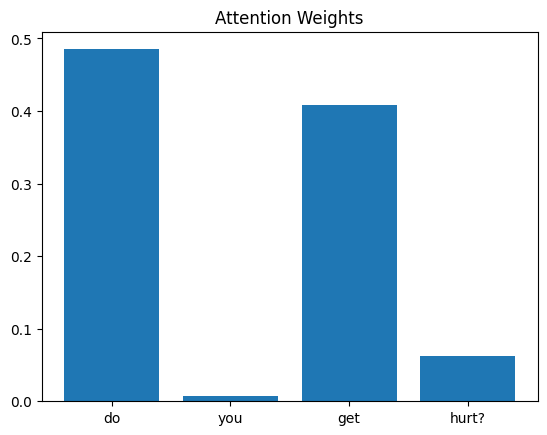

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


### Task 1 — Understand Attention Weights

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [7]:
# function to draw the attention weights of any question
def show_attention(question):
    question = question.lower()
    seq = tokenizer.texts_to_sequences([question])[0]
    words = [tokenizer.index_word[i] for i in seq]

    padded = pad_sequences([seq], maxlen=X.shape[1], padding="post")
    padded = torch.tensor(padded, dtype=torch.long)

    with torch.no_grad():
        prediction, weights = model(padded)

    w = weights[0, :len(words)].tolist()

    plt.bar(words, w)
    plt.title("Attention Weights: " + question)
    plt.show()

    print("Highest attention word:", words[w.index(max(w))], "->", round(max(w), 4))
    print("Predicted answer:", df[df["answer_id"] == prediction.argmax(1).item()]["answer"].iloc[0])
    print()

Highest attention word: do -> 0.485
Predicted answer: I don't have a body.

Highest attention word: who -> 0.5923
Predicted answer: People created me.

Highest attention word: think -> 0.5062
Predicted answer: I'm better at answering questions.



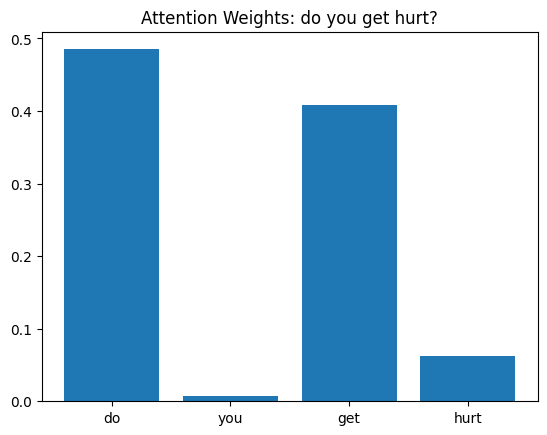

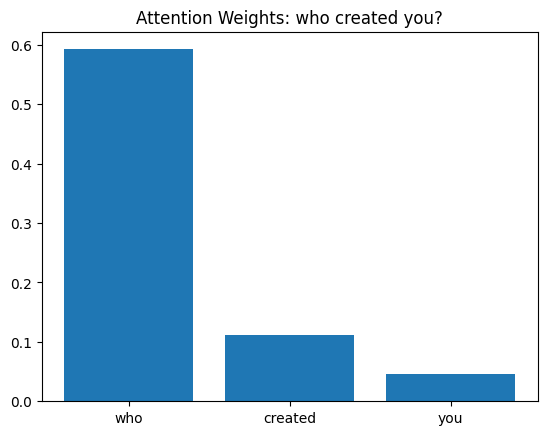

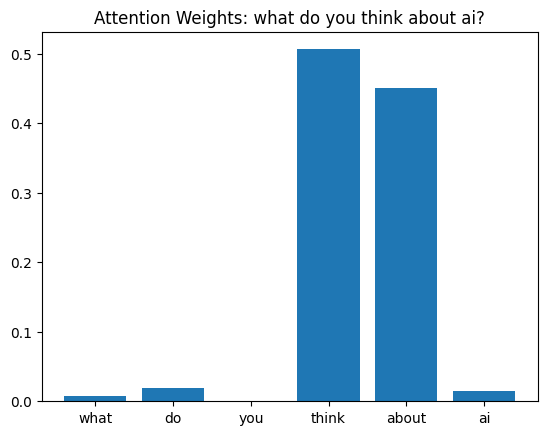

In [8]:
# Task 1: three different questions
show_attention("do you get hurt?")
show_attention("who created you?")
show_attention("what do you think about AI?")

**Highest attention word in each question:**
- "do you get hurt?" -> **do** (0.485)
- "who created you?" -> **who** (0.592)
- "what do you think about AI?" -> **think** (0.506)

**Answer:** Not always. In the first two questions the highest weight went to the question words ("do", "who"), and the more important words ("hurt" = 0.063, "created" = 0.112) got small weights. In the third question the model focused on "think" and "about" and almost ignored "ai" (0.015), which is the important word, so it predicted a wrong answer. So the highest attention words do not always look important for understanding the question. The reason is that this is a small RNN trained only 50 epochs, and its accuracy on the training data is low (about 38%).

### Task 2 — Compare Attention for Similar Questions

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Highest attention word: who -> 0.5923
Predicted answer: People created me.

Highest attention word: which -> 0.5262
Predicted answer: People created me.



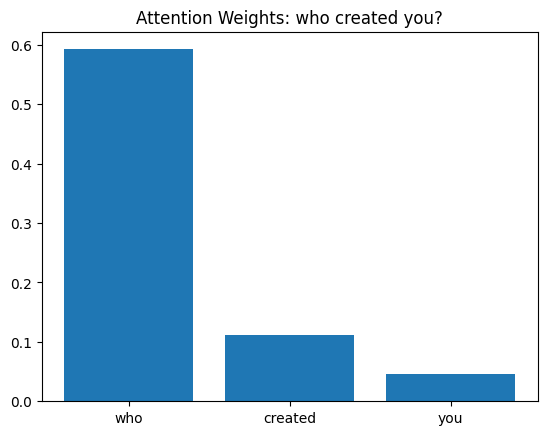

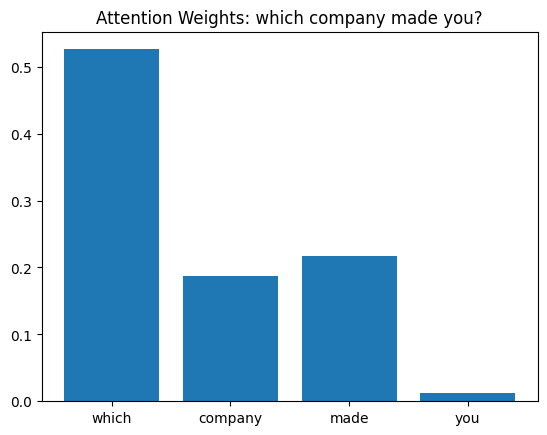

In [9]:
# Task 2: two questions with the same meaning but different words
show_attention("who created you?")
show_attention("which company made you?")

I compared "who created you?" and "which company made you?" (both have the same answer: "People created me.").

- "who created you?" -> highest word: **who** (0.592)
- "which company made you?" -> highest word: **which** (0.526), then "made" (0.217) and "company" (0.188)

**Answer:** The model focused on different words, but in both questions it gave the highest weight to the first question word ("who" / "which"). Both questions got the same predicted answer. This suggests that attention only gives a weight to each word depending on what the model learned from the training data, it does not really understand the meaning, and similar questions can get attention on different words.